In [ ]:
import pandas as pd
import numpy as np
from glob import glob
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import LassoCV

datasets = glob("Data-Buenos-Aires\data\*.csv")
datasets

In [ ]:
files = []

for x in datasets:
    data = pd.read_csv(x)  # <--- Read the CSV file at path x
    files.append(data)

len(files)

In [3]:
df = pd.concat(files, ignore_index=True)  # pd.concat(files, ignore_index=True)
df.head()

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499",180000.0,USD,2729232.0,180000.0,120.0,110.0,1500.000000,1636.363636,NaN,4.0,NaN,http://villa-crespo.properati.com.ar/12egq_ven...
1,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,NaN,250000.0,USD,3790600.0,250000.0,117.0,120.0,2136.752137,2083.333333,NaN,4.0,NaN,http://ramos-mejia.properati.com.ar/s7pd_venta...
2,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Cast...,"-34.6497002,-58.658073",410000.0,USD,6216584.0,410000.0,410.0,220.0,1000.000000,1863.636364,NaN,NaN,NaN,http://castelar-moron.properati.com.ar/11vgn_v...
3,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Tres de Fe...,"-34.5957086,-58.5669503",180000.0,USD,2729232.0,180000.0,200.0,135.0,900.000000,1333.333333,NaN,5.0,NaN,http://tres-de-febrero.properati.com.ar/7f7u_v...
4,sell,apartment,|Argentina|Capital Federal|Chacarita|,"-34.5846508988,-58.4546932614",129000.0,USD,1955949.6,129000.0,76.0,70.0,1697.368421,1842.857143,NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...


In [4]:
def merged_files(data):
    """Merge multiple CSV files matching a pattern into a single DataFrame."""
    return pd.concat([pd.read_csv(file) for file in glob(data)], ignore_index=True)

# Usage
merged_files(r"C:\Users\Ulikhifun Mike\Data-Buenos-aires\data\*").info()

<class 'pandas.DataFrame'>
RangeIndex: 43029 entries, 0 to 43028
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   operation                   43029 non-null  str    
 1   property_type               43029 non-null  str    
 2   place_with_parent_names     43029 non-null  str    
 3   lat-lon                     34734 non-null  str    
 4   price                       38073 non-null  float64
 5   currency                    38072 non-null  str    
 6   price_aprox_local_currency  38073 non-null  float64
 7   price_aprox_usd             38073 non-null  float64
 8   surface_total_in_m2         29871 non-null  float64
 9   surface_covered_in_m2       36420 non-null  float64
 10  price_usd_per_m2            24449 non-null  float64
 11  price_per_m2                32642 non-null  float64
 12  floor                       6505 non-null   float64
 13  rooms                       23806 non-null

In [5]:
# code for filtering a DataFrame

(
    df
    .loc[lambda x: x["place_with_parent_names"].str.contains("Capital Federal")]
    .query('property_type == "apartment"')
    .query('price_aprox_usd < 400_000')
    .head() 
)

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499",180000.0,USD,2729232.0,180000.0,120.0,110.0,1500.000000,1636.363636,NaN,4.0,NaN,http://villa-crespo.properati.com.ar/12egq_ven...
4,sell,apartment,|Argentina|Capital Federal|Chacarita|,"-34.5846508988,-58.4546932614",129000.0,USD,1955949.6,129000.0,76.0,70.0,1697.368421,1842.857143,NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...
9,sell,apartment,|Argentina|Capital Federal|Villa Luro|,"-34.6389789,-58.500115",87000.0,USD,1319128.8,87000.0,48.0,42.0,1812.500000,2071.428571,NaN,NaN,NaN,http://villa-luro.properati.com.ar/12m82_venta...
11,sell,apartment,|Argentina|Capital Federal|Once|,"-34.6050060697,-58.4001162302",60000.0,USD,909744.0,60000.0,28.0,28.0,2142.857143,2142.857143,NaN,1.0,NaN,http://once.properati.com.ar/zz0q_venta_depart...
20,sell,apartment,|Argentina|Capital Federal|San Nicolás|,"-34.603898,-58.378617",69000.0,USD,1046205.6,69000.0,NaN,22.0,NaN,3136.363636,23.0,2.0,NaN,http://san-nicolas.properati.com.ar/rnju_venta...


In [6]:
def filter_df(data):
    return (
        data
        .loc[lambda x: x["place_with_parent_names"].str.contains("Capital Federal")]
        .query('property_type == "apartment"')
        .query('price_aprox_usd < 400_000') 
    )
filter_df(df)

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499",180000.0,USD,2729232.00,180000.0,120.0,110.0,1500.000000,1636.363636,NaN,4.0,NaN,http://villa-crespo.properati.com.ar/12egq_ven...
4,sell,apartment,|Argentina|Capital Federal|Chacarita|,"-34.5846508988,-58.4546932614",129000.0,USD,1955949.60,129000.0,76.0,70.0,1697.368421,1842.857143,NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...
9,sell,apartment,|Argentina|Capital Federal|Villa Luro|,"-34.6389789,-58.500115",87000.0,USD,1319128.80,87000.0,48.0,42.0,1812.500000,2071.428571,NaN,NaN,NaN,http://villa-luro.properati.com.ar/12m82_venta...
11,sell,apartment,|Argentina|Capital Federal|Once|,"-34.6050060697,-58.4001162302",60000.0,USD,909744.00,60000.0,28.0,28.0,2142.857143,2142.857143,NaN,1.0,NaN,http://once.properati.com.ar/zz0q_venta_depart...
20,sell,apartment,|Argentina|Capital Federal|San Nicolás|,"-34.603898,-58.378617",69000.0,USD,1046205.60,69000.0,NaN,22.0,NaN,3136.363636,23.0,2.0,NaN,http://san-nicolas.properati.com.ar/rnju_venta...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42990,sell,apartment,|Argentina|Capital Federal|Liniers|,"-34.6395276,-58.5196662",290000.0,USD,4397096.00,290000.0,93.0,83.0,3118.279570,3493.975904,NaN,4.0,NaN,http://liniers.properati.com.ar/t11h_venta_dep...
42997,sell,apartment,|Argentina|Capital Federal|Palermo|,"-34.5978249,-58.4164389",150000.0,USD,2274360.00,150000.0,92.0,45.0,1630.434783,3333.333333,NaN,1.0,1000.0,http://palermo.properati.com.ar/zowv_venta_dep...
43001,sell,apartment,|Argentina|Capital Federal|Mataderos|,"-34.6522327,-58.4907391",65000.0,USD,985556.00,65000.0,42.0,42.0,1547.619048,1547.619048,NaN,2.0,1000.0,http://mataderos.properati.com.ar/11zcp_venta_...
43002,sell,apartment,|Argentina|Capital Federal|Mataderos|,"-34.648761,-58.50018",91440.0,USD,1386449.85,91440.0,NaN,48.0,NaN,1905.000000,6.0,2.0,NaN,http://mataderos.properati.com.ar/xlo5_venta_d...


In [7]:
# handling outliers
# Keep only properties between the 10th and 90th percentile of surface area
def outliers_df(data):
    return (
        data
        .loc[lambda x: x["surface_covered_in_m2"].between(x["surface_covered_in_m2"].quantile(0.1), x["surface_covered_in_m2"].quantile(0.9))]  
    )

# Test the function
check_outliers = outliers_df(df)
check_outliers.head()

,operation,property_type,place_with_parent_names,lat-lon,price,currency,price_aprox_local_currency,price_aprox_usd,surface_total_in_m2,surface_covered_in_m2,price_usd_per_m2,price_per_m2,floor,rooms,expenses,properati_url
0,sell,apartment,|Argentina|Capital Federal|Villa Crespo|,"-34.6047834183,-58.4586812499",180000.0,USD,2729232.0,180000.0,120.0,110.0,1500.000000,1636.363636,NaN,4.0,NaN,http://villa-crespo.properati.com.ar/12egq_ven...
1,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|La Matanza...,NaN,250000.0,USD,3790600.0,250000.0,117.0,120.0,2136.752137,2083.333333,NaN,4.0,NaN,http://ramos-mejia.properati.com.ar/s7pd_venta...
2,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Morón|Cast...,"-34.6497002,-58.658073",410000.0,USD,6216584.0,410000.0,410.0,220.0,1000.000000,1863.636364,NaN,NaN,NaN,http://castelar-moron.properati.com.ar/11vgn_v...
3,sell,house,|Argentina|Bs.As. G.B.A. Zona Oeste|Tres de Fe...,"-34.5957086,-58.5669503",180000.0,USD,2729232.0,180000.0,200.0,135.0,900.000000,1333.333333,NaN,5.0,NaN,http://tres-de-febrero.properati.com.ar/7f7u_v...
4,sell,apartment,|Argentina|Capital Federal|Chacarita|,"-34.5846508988,-58.4546932614",129000.0,USD,1955949.6,129000.0,76.0,70.0,1697.368421,1842.857143,NaN,NaN,NaN,http://chacarita.properati.com.ar/10qlv_venta_...


In [8]:
# Split "lat-lon" on comma, take piece [0] as latitude
# Split "lat-lon" on comma, take piece [1] as longitude
# Split "place_with_parent_names" on pipe, take piece [3] as neighborhood

def modify_cols(data):
    return (
        data
        .assign(
            lat=lambda x: x["lat-lon"].str.split(",", expand=True)[0].astype(float),      
            lon=lambda x: x["lat-lon"].str.split(",", expand=True)[1].astype(float),      
            neighborhood=lambda x: x["place_with_parent_names"].str.split("|", expand=True)[3]           
        )
    )

check_cols = modify_cols(df)
check_cols.info()

<class 'pandas.DataFrame'>
RangeIndex: 43029 entries, 0 to 43028
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   operation                   43029 non-null  str    
 1   property_type               43029 non-null  str    
 2   place_with_parent_names     43029 non-null  str    
 3   lat-lon                     34734 non-null  str    
 4   price                       38073 non-null  float64
 5   currency                    38072 non-null  str    
 6   price_aprox_local_currency  38073 non-null  float64
 7   price_aprox_usd             38073 non-null  float64
 8   surface_total_in_m2         29871 non-null  float64
 9   surface_covered_in_m2       36420 non-null  float64
 10  price_usd_per_m2            24449 non-null  float64
 11  price_per_m2                32642 non-null  float64
 12  floor                       6505 non-null   float64
 13  rooms                       23806 non-null

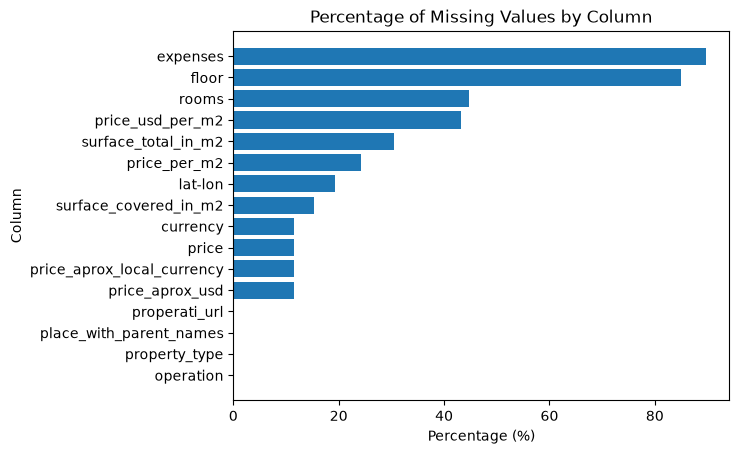

In [9]:
# Percentage of missing values by column
nan_columns_percentage = (df.isna().sum(axis=0) * 100 / len(df)).sort_values()

fig, ax = plt.subplots()

# Horizontal bar plot
ax.barh(y=nan_columns_percentage.index, width=nan_columns_percentage)
ax.set_title('Percentage of Missing Values by Column')
ax.set_xlabel('Percentage (%)')
ax.set_ylabel('Column')
plt.show()

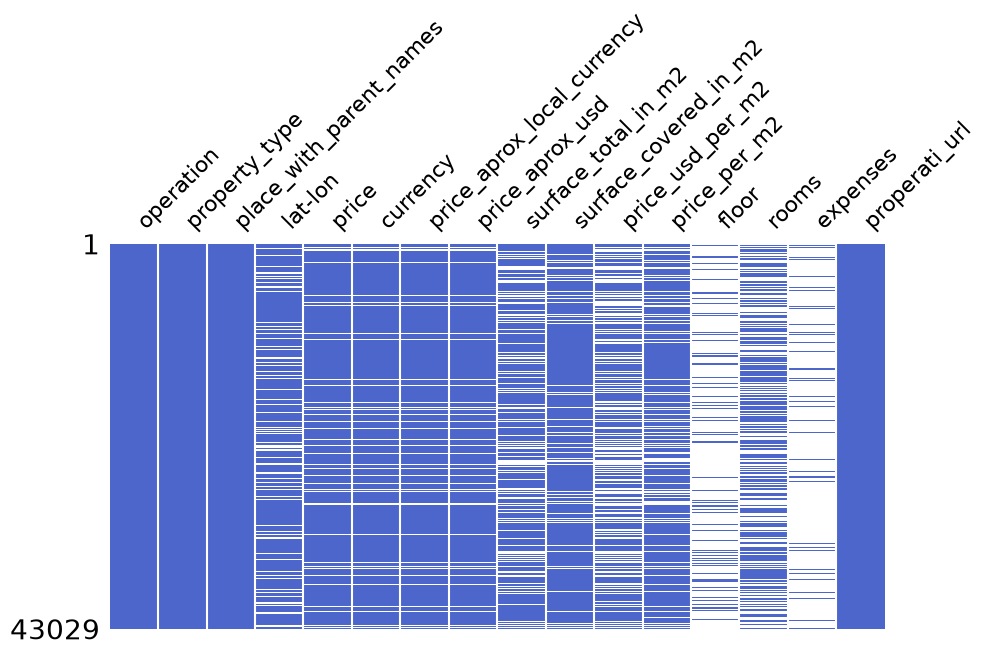

In [10]:
import missingno as msno
import matplotlib.pyplot as plt

# Plot missing values with royal blue color
fig, ax = plt.subplots(figsize=(10, 5))

msno.matrix(
    df,
    color=(0.3, 0.4, 0.8),
    ax=ax,
    sparkline=False
)

plt.show()

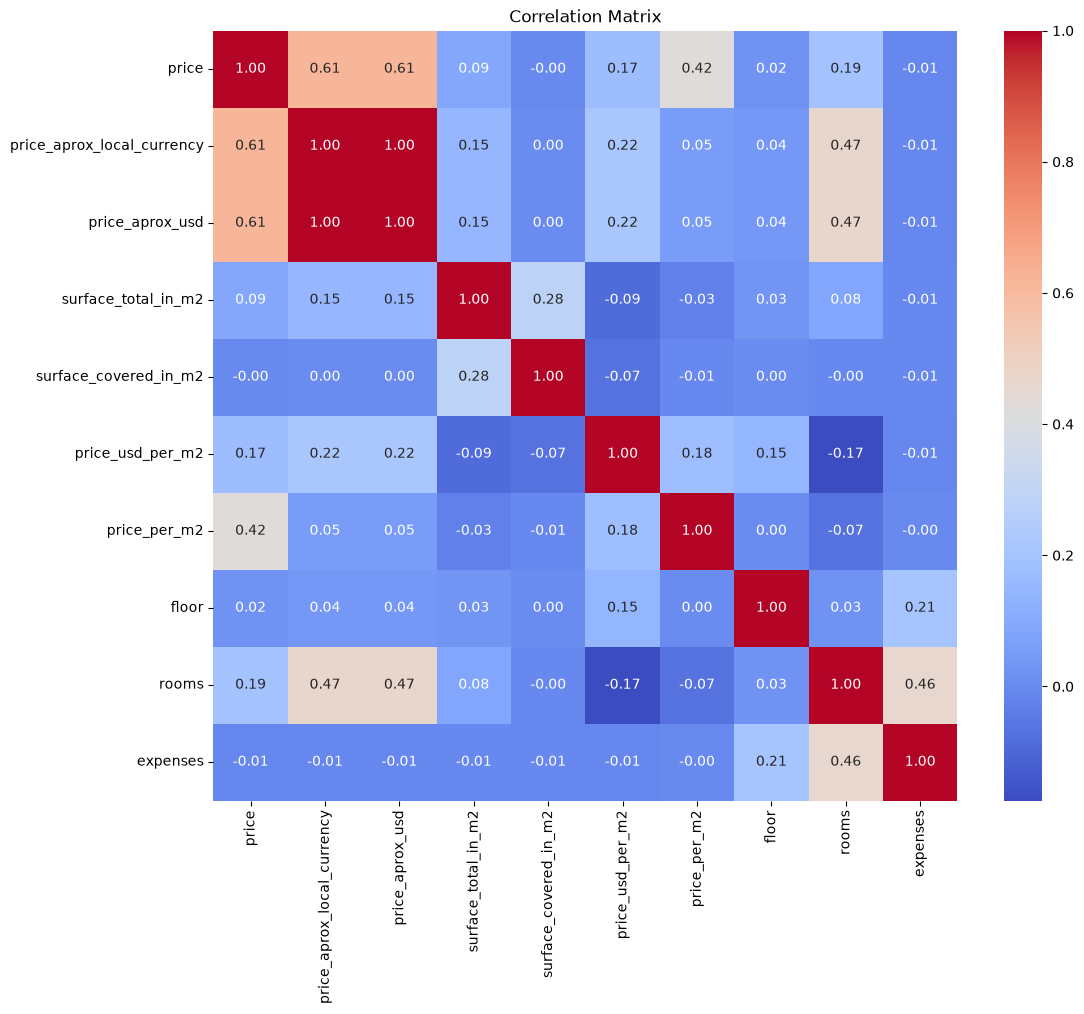

In [11]:
# Multicollinearity Analysis

import seaborn as sns

# Calculate correlation matrix for numeric columns
corr_matrix = df.select_dtypes(include='number').corr()  

# Plot heatmap
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Correlation Matrix')
plt.show()

In [12]:
# Dropping Unnecessary Columns, High missingness (>50%), Data leakage, Multicollinearity (surface_total_in_m2), Unique identifiers (properati_url), Already extracted, Single-value columns

def clean_files(file_path):
    """Final function to complete the cleaning process"""
    drop_cols = [
        "lat-lon", "place_with_parent_names",
        "floor", "expenses", "rooms", "price",
        "price_aprox_local_currency", "price_usd_per_m2",
        "price_per_m2", "operation", "property_type", "currency",
        "properati_url", "surface_total_in_m2"
    ]

    return (
        merged_files(file_path)      # <--- Initial DataFrame
        .pipe(filter_df)             # <--- Filter to Capital Federal apartments
        .pipe(outliers_df)           # <--- Remove outliers
        .pipe(modify_cols)           # <--- Create new columns
        .drop(columns=drop_cols)     # <--- Drop unnecessary columns
        .dropna()                    # <--- Drop rows with missing values
    )

clean_df = clean_files(r"C:\Users\Ulikhifun Mike\Data-Buenos-aires\data\*")
clean_df.info()
clean_df

<class 'pandas.DataFrame'>
Index: 6247 entries, 4 to 43021
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   price_aprox_usd        6247 non-null   float64
 1   surface_covered_in_m2  6247 non-null   float64
 2   lat                    6247 non-null   float64
 3   lon                    6247 non-null   float64
 4   neighborhood           6247 non-null   str    
dtypes: float64(4), str(1)
memory usage: 350.2 KB


,price_aprox_usd,surface_covered_in_m2,lat,lon,neighborhood
4,129000.0,70.0,-34.584651,-58.454693,Chacarita
9,87000.0,42.0,-34.638979,-58.500115,Villa Luro
29,118000.0,54.0,-34.615847,-58.459957,Caballito
40,57000.0,42.0,-34.625222,-58.382382,Constitución
41,90000.0,50.0,-34.610610,-58.412511,Once
...,...,...,...,...,...
42990,290000.0,83.0,-34.639528,-58.519666,Liniers
42997,150000.0,45.0,-34.597825,-58.416439,Palermo
43001,65000.0,42.0,-34.652233,-58.490739,Mataderos
43002,91440.0,48.0,-34.648761,-58.500180,Mataderos


In [13]:
# Start with cleaned data, select relevant columns, and show first few rows
sample_df = (
    clean_df
    [['neighborhood', 'price_aprox_usd']]  # <--- Select only these two columns
    .head(5)  # <--- Get first 5 rows to see the original format
)

print("BEFORE One-Hot Encoding:")
print(sample_df)
print(f"\nUnique neighborhoods in sample: {sample_df['neighborhood'].unique()}")

BEFORE One-Hot Encoding:
    neighborhood  price_aprox_usd
4      Chacarita         129000.0
9     Villa Luro          87000.0
29     Caballito         118000.0
40  Constitución          57000.0
41          Once          90000.0

Unique neighborhoods in sample: <ArrowStringArray>
['Chacarita', 'Villa Luro', 'Caballito', 'Constitución', 'Once']
Length: 5, dtype: str


In [14]:
# Transform categorical column into multiple binary columns
encoded_df = (
    sample_df
    .assign(
        is_palermo = (sample_df["neighborhood"] == "Palermo").astype(int),  # <--- Create binary column: 1 if Palermo, 0 otherwise
        is_caballito = (sample_df["neighborhood"] == "Caballito").astype(int),  # <--- Create binary column: 1 if Caballito, 0 otherwise
        is_villa_luro = (sample_df["neighborhood"] == "Villa Luro").astype(int),  # <--- Create binary column: 1 if Villa Luro, 0 otherwise
    )
    .drop(columns=['neighborhood'])  # <--- Remove the original text column (I no longer need it)
)

print("\nAFTER One-Hot Encoding:")
print(encoded_df)


AFTER One-Hot Encoding:
    price_aprox_usd  is_palermo  is_caballito  is_villa_luro
4          129000.0           0             0              0
9           87000.0           0             0              1
29         118000.0           0             1              0
40          57000.0           0             0              0
41          90000.0           0             0              0


In [15]:
df = clean_df

# Define target and features
target = "price_aprox_usd"
feature = [col for col in df.columns if col not in target]

# Split into features and target
X = df[feature] 
y = df[target] 

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (6247, 4)
Target shape: (6247,)


In [16]:
X_train_4, X_test_4, y_train_4, y_test_4 = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training rows: {len(X_train_4)}")
print(f"Testing rows: {len(X_test_4)}")

Training rows: 4997
Testing rows: 1250


In [17]:
# Here we apply the DRY (Don't Repeat Yourself) principle: wrap the repeated logic into a single reusable function.

from sklearn.metrics import mean_squared_error
import numpy as np

def get_rmse_4(model, X, y_true):
    """
    Calculate RMSE for a given model and dataset.

    Parameters:
    -----------
    model : fitted sklearn model or pipeline
    X : features (DataFrame or array)
    y_true : true target values

    Returns:
    --------
    float : RMSE value
    """
    y_pred = model.predict(X)  # <--- X
    rmse = root_mean_squared_error(y_true, y_pred) # <--- y_true, y_pred
    return np.sqrt(mean_squared_error(y_true, y_pred))

# Test the function
print("Function created successfully!")

Function created successfully!


In [18]:
# Calculate mean
y_mean_4 = y_train_4.mean()

# Create baseline predictions
y_pred_baseline_train = [y_mean_4] * len(y_train_4)
y_pred_baseline_test = [y_mean_4] * len(y_test_4)

# Calculate RMSE
rmse_base_train = root_mean_squared_error(y_train_4, y_pred_baseline_train)  
rmse_base_test = root_mean_squared_error(y_test_4, y_pred_baseline_test)  

print(f"Baseline Train RMSE: ${rmse_base_train:,.2f}")
print(f"Baseline Test RMSE: ${rmse_base_test:,.2f}")

Baseline Train RMSE: $59,700.25
Baseline Test RMSE: $57,576.13


In [19]:
# Linear Regression Model

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from category_encoders import OneHotEncoder

model_linear_4 = make_pipeline(
    OneHotEncoder(use_cat_names=True),
    StandardScaler(),
    LinearRegression()
)

model_linear_4.fit(X_train_4, y_train_4)  # X_train_4, y_train_4

rmse_linear_train = get_rmse_4(model_linear_4, X_train_4, y_train_4)  
rmse_linear_test = get_rmse_4(model_linear_4, X_test_4, y_test_4)  

print(f"Linear Regression Train RMSE: ${rmse_linear_train:,.2f}")
print(f"Linear Regression Test RMSE: ${rmse_linear_test:,.2f}")

Linear Regression Train RMSE: $34,200.43
Linear Regression Test RMSE: $33,088.37


In [22]:
# Ridge Regression (RidgeCV) evaluation

model_ridge_4 = make_pipeline(
    OneHotEncoder(use_cat_names=True),  # True
    StandardScaler(),
    RidgeCV(alphas=np.logspace(-2, 4, 100))  # np.logspace(-2, 4, 100)
)

model_ridge_4.fit(X_train_4, y_train_4)  # X_train_4, y_train_4

rmse_ridge_train = get_rmse_4(model_ridge_4, X_train_4, y_train_4)  # model_ridge_4, X_train_4, y_train_4
rmse_ridge_test = get_rmse_4(model_ridge_4, X_test_4, y_test_4)  # model_ridge_4, X_test_4, y_test_4

# Extract the tuned alpha value
alpha_ridge_chosen = model_ridge_4.named_steps["ridgecv"].alpha_
print(f"Best Ridge alpha: {alpha_ridge_chosen:.6f}")
print(f"Ridge Train RMSE: ${rmse_ridge_train:,.2f}")
print(f"Ridge Test RMSE: ${rmse_ridge_test:,.2f}")

Best Ridge alpha: 43.287613
Ridge Train RMSE: $34,203.95
Ridge Test RMSE: $33,071.27


In [25]:
# Lasso Regression (LassoCV)

model_lasso_4 = make_pipeline(
    OneHotEncoder(use_cat_names=True),  # True
    StandardScaler(),
    LassoCV(alphas=np.logspace(-4, 2, 100), max_iter=10000)  # np.logspace(-4, 2, 100)
)

model_lasso_4.fit(X_train_4, y_train_4)  # X_train_4, y_train_4

rmse_lasso_train = get_rmse_4(model_lasso_4, X_train_4, y_train_4)  # model_lasso_4, X_train_4, y_train_4
rmse_lasso_test = get_rmse_4(model_lasso_4, X_test_4, y_test_4)  # model_lasso_4, X_test_4, y_test_4

# Extract the tuned alpha value
alpha_lasso_chosen = model_lasso_4.named_steps["lassocv"].alpha_
print(f"Best Lasso alpha: {alpha_lasso_chosen:.6f}")
print(f"Lasso Train RMSE: ${rmse_lasso_train:,.2f}")
print(f"Lasso Test RMSE: ${rmse_lasso_test:,.2f}")

Best Lasso alpha: 32.745492
Lasso Train RMSE: $34,203.20
Lasso Test RMSE: $33,069.18


In [26]:
# Build Results Table
data_4 = {
    "Model": ["Baseline", "Linear Regression", "Ridge (CV-tuned)", "Lasso (CV-tuned)"],
    "Train_RMSE": [
        rmse_base_train,
        rmse_linear_train,  # rmse_linear_train
        rmse_ridge_train,  # rmse_ridge_train
        rmse_lasso_train   # rmse_lasso_train
    ],
    "Test_RMSE": [
        rmse_base_test,
        rmse_linear_test,  # rmse_linear_test
        rmse_ridge_test,  # rmse_ridge_test
        rmse_lasso_test   # rmse_lasso_test
    ]
}

df_results_4 = pd.DataFrame(data_4)

# Calculate Generalization Gap
df_results_4["Gap"] = df_results_4["Test_RMSE"] - df_results_4["Train_RMSE"]

# Set Model as index for better display
df_results_4 = df_results_4.set_index("Model")

print("\n" + "="*60)
print("MODEL COMPARISON TABLE")
print("="*60)
print(df_results_4.round(2))
print("="*60)


MODEL COMPARISON TABLE
                   Train_RMSE  Test_RMSE      Gap
Model                                            
Baseline             59700.25   57576.13 -2124.12
Linear Regression    34200.43   33088.37 -1112.06
Ridge (CV-tuned)     34203.95   33071.27 -1132.68
Lasso (CV-tuned)     34203.20   33069.18 -1134.01


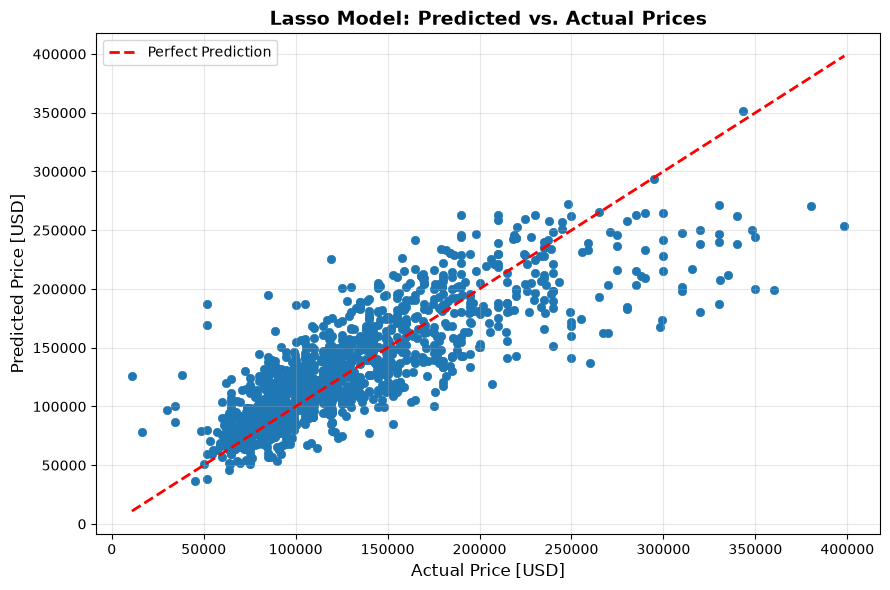

In [27]:
# Creating a predicted vs. actual scatter plot for the Lasso model.

y_pred_lasso_4 = model_lasso_4.predict(X_test_4)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(y_test_4, y_pred_lasso_4, linewidth=0.5)

ideal_line = np.linspace(y_test_4.min(), y_test_4.max(), 100)
ax.plot(ideal_line, ideal_line, color="red", linestyle="--", linewidth=2, label="Perfect Prediction")

ax.set_xlabel("Actual Price [USD]", fontsize=12)
ax.set_ylabel("Predicted Price [USD]", fontsize=12)
ax.set_title("Lasso Model: Predicted vs. Actual Prices", fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

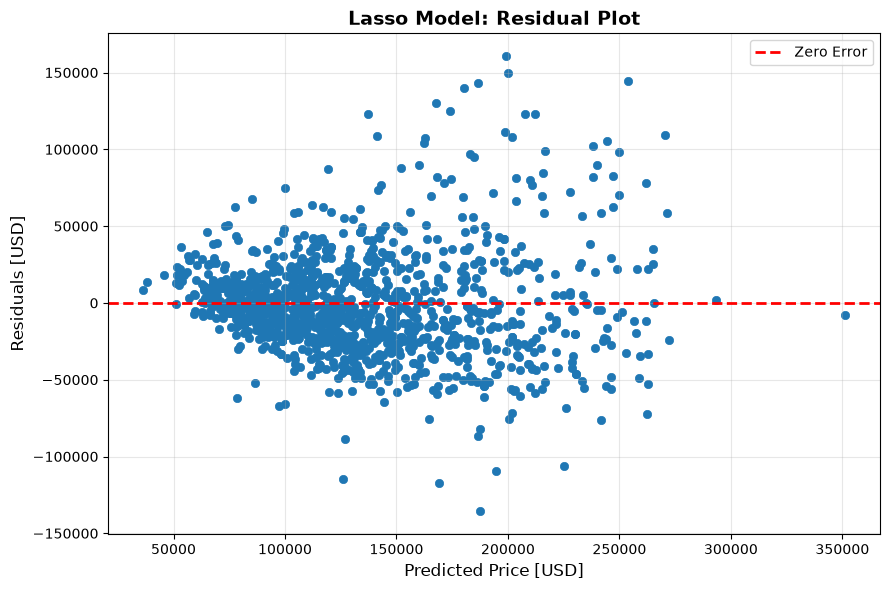

In [28]:
# Creating a residual plot (actual − predicted vs. predicted values) for the Lasso model.

residuals_4 = y_test_4 - y_pred_lasso_4

fig_res, ax_res = plt.subplots(figsize=(9, 6))
ax_res.scatter(y_pred_lasso_4, residuals_4, linewidth=0.5)
ax_res.axhline(y=0, color='r', linestyle='--', linewidth=2, label='Zero Error')
ax_res.set_xlabel("Predicted Price [USD]", fontsize=12)
ax_res.set_ylabel("Residuals [USD]", fontsize=12)
ax_res.set_title("Lasso Model: Residual Plot", fontsize=14, fontweight='bold')
ax_res.legend(fontsize=10)
ax_res.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
# Extract from pipeline. fix heteroscedasticity (non-constant error variance)

coefs_4 = model_lasso_4.named_steps["lassocv"].coef_  # .coef_
feature_names_4 = model_lasso_4.named_steps["onehotencoder"].get_feature_names_out()  # .get_feature_names_out()

feat_imp_4 = pd.Series(coefs_4, index=feature_names_4)  # coefs_4, index=feature_names_4

print(f"Total features: {len(feat_imp_4)}")
print(f"Non-zero features: {(feat_imp_4 != 0).sum()}")
print("\nTop 5 positive coefficients:")
print(feat_imp_4.nlargest(5))
print("\nTop 5 negative coefficients:")
print(feat_imp_4.nsmallest(5))

Total features: 59
Non-zero features: 58

Top 5 positive coefficients:
surface_covered_in_m2         40346.180348
neighborhood_Puerto Madero     9793.898166
neighborhood_Palermo           9684.053726
lat                            8837.497355
neighborhood_Belgrano          7270.101180
dtype: float64

Top 5 negative coefficients:
neighborhood_Balvanera      -5420.759156
neighborhood_Boca           -4734.035389
neighborhood_Once           -4527.997089
neighborhood_Congreso       -3353.222368
neighborhood_Constitución   -2736.586612
dtype: float64


In [30]:
# Calculate how many features have been set to exactly zero by the Lasso model

zero_features_4 = (feat_imp_4 == 0).sum()  # (feat_imp_4 == 0).sum()
total_features_4 = len(feat_imp_4)
percent_eliminated_4 = (zero_features_4 / total_features_4) * 100

print(f"Lasso eliminated {zero_features_4} out of {total_features_4} features.")
print(f"Percentage eliminated: {percent_eliminated_4:.1f}%")

Lasso eliminated 1 out of 59 features.
Percentage eliminated: 1.7%


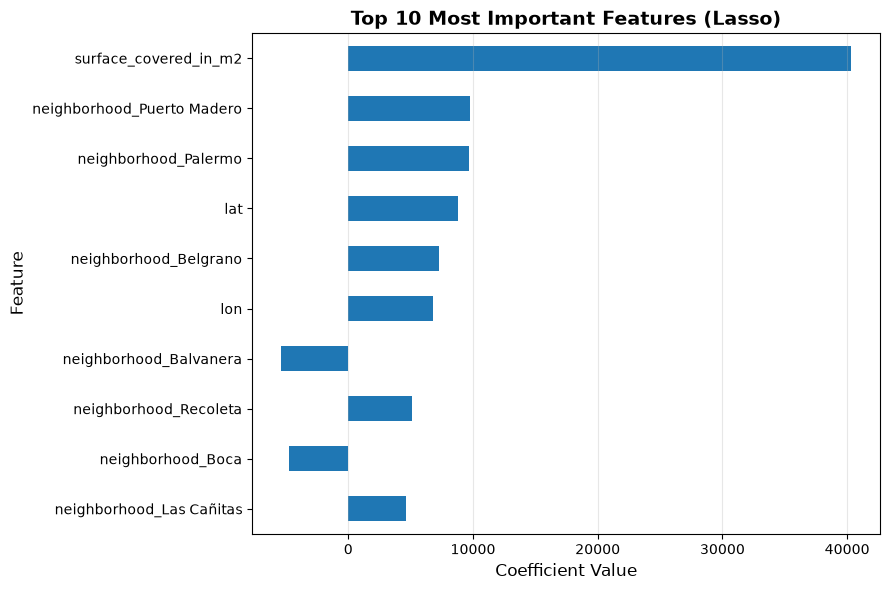

In [31]:
# Visualizing the Top Features

fig_feat, ax_feat = plt.subplots(figsize=(9, 6))
feat_imp_4.sort_values(key=abs).tail(10).plot(kind="barh", ax=ax_feat)
ax_feat.set_title("Top 10 Most Important Features (Lasso)", fontsize=14, fontweight='bold')
ax_feat.set_xlabel("Coefficient Value", fontsize=12)
ax_feat.set_ylabel("Feature", fontsize=12)
ax_feat.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
top_feature_4 = feat_imp_4.idxmax()
top_coefficient_4 = feat_imp_4.max()

print(f"The most influential positive feature is: {top_feature_4}")
print(f"Its coefficient is: ${top_coefficient_4:,.2f}")

The most influential positive feature is: surface_covered_in_m2
Its coefficient is: $40,346.18


In [35]:
# Compare test RMSE values
test_rmse = {
    "Linear Regression": rmse_linear_test,
    "Ridge": rmse_ridge_test,
    "Lasso": rmse_lasso_test
}

# Select the model with the lowest test RMSE
best_model_name = min(test_rmse, key=test_rmse.get)

models = {
    "Linear Regression": model_linear_4,
    "Ridge": model_ridge_4,
    "Lasso": model_lasso_4
}

best_model = models[best_model_name]

print("Best model:", best_model_name)
print(f"Test RMSE: ${test_rmse[best_model_name]:,.2f}")

# Generate predictions
y_test_pred = best_model.predict(X_test_4)

# Create submission file
submission_df = X_test_4.copy()
submission_df["price_aprox_usd"] = y_test_pred
submission_df = submission_df.reset_index(drop=True)


print("Submission saved as submission.csv")
display(submission_df.head())

Best model: Lasso
Test RMSE: $33,069.18
Submission saved as submission.csv


,surface_covered_in_m2,lat,lon,neighborhood,price_aprox_usd
0,35.0,-34.562909,-58.465303,Belgrano,118424.089342
1,56.0,-34.626440,-58.459419,Flores,114165.955038
2,83.0,-34.606622,-58.384362,Monserrat,181766.609188
3,42.0,-34.631591,-58.370191,Barracas,92744.811217
4,31.0,-34.637484,-58.460145,Flores,54712.073745


In [36]:
submission_df.to_csv("submission.csv", index=False)